# Phases 5-7 — Imbalance, Modeling & Threshold Tuning

This notebook ties the modeling story together by calling the tested `src/` modules:
- **Phase 5:** class imbalance (class weights vs SMOTE)
- **Phase 6:** train & compare LogReg / RF / XGBoost / SVM, ranked by PR-AUC
- **Phase 7:** evaluate the best model, tune the decision threshold by business cost

We lead with **recall and PR-AUC**, never accuracy (it is ~99.8% for everything).

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option('display.float_format', '{:.4f}'.format)

FIG = Path.cwd().parent / 'reports' / 'figures'

## Phase 5 — Class imbalance: what are our options?
We resample TRAIN ONLY. The test set stays at ~0.17% fraud.

In [2]:
from src.imbalance import class_weight_for, scale_pos_weight_for, apply_smote

train = pd.read_parquet(Path.cwd().parent / 'data' / 'processed' / 'train.parquet')
X_train, y_train = train.drop(columns=['Class']), train['Class']

print('Balanced class weights:', {k: round(v,1) for k,v in class_weight_for(y_train).items()})
print('XGBoost scale_pos_weight:', round(scale_pos_weight_for(y_train),1))
_ = apply_smote(X_train, y_train)   # demo: 378 fraud -> balanced (TRAIN only)

Balanced class weights: {0: 0.5, 1: 300.2}
XGBoost scale_pos_weight: 599.5
[SMOTE] before: {0: 226602, 1: 378}  ->  after: {0: 226602, 1: 226602}


## Phase 6 — Train & compare four models
Imbalance handled via class weights (LogReg/RF/SVM) and scale_pos_weight (XGBoost).
SVM trains on a subsample for speed (stated honestly).

In [3]:
from src.models import train_and_compare

results = train_and_compare(save_best=True)
results

Train (226980, 30) | Test (56746, 30) | test fraud: 95 (0.167%)



  LogisticRegression   recall=0.874  prec=0.056  PR-AUC=0.672  (0.2s)


  RandomForest         recall=0.716  prec=0.971  PR-AUC=0.808  (12.1s)


  XGBoost              recall=0.789  prec=0.862  PR-AUC=0.823  (0.8s)
  SVM (subsample): training on 30,000-row subsample (speed)...


  SVM (subsample)      recall=0.484  prec=0.414  PR-AUC=0.474  (1.7s)

Saved best model (XGBoost) -> models/best_xgboost.joblib


,model,recall,precision,f1,roc_auc,pr_auc,fit_secs
0,XGBoost,0.7895,0.8621,0.8242,0.9659,0.8228,0.8000
1,RandomForest,0.7158,0.9714,0.8242,0.9445,0.8082,12.1000
2,LogisticRegression,0.8737,0.0562,0.1057,0.9657,0.6719,0.2000
3,SVM (subsample),0.4842,0.4144,0.4466,0.9365,0.4738,1.7000


**Read it as a business person:** XGBoost wins on PR-AUC. Logistic Regression has a *great* ROC-AUC but catastrophic 5.6% precision — proof that **ROC-AUC flatters models under heavy imbalance** and PR-AUC is the honest metric.

## Phase 7 — Evaluate best model & tune the threshold
A model outputs a probability; the business value is *where we draw the line*.

In [4]:
from src.evaluate import (load_test_and_model, plot_curves,
                          threshold_for_recall, cost_optimal_threshold, confusion_at)

X_test, y_test, y_proba = load_test_and_model()
plot_curves(y_test, y_proba)

print('Default 0.50      :', confusion_at(y_test, y_proba, 0.50, 'default'))
print('90% recall target :', threshold_for_recall(y_test, y_proba, 0.90))
best, _ = cost_optimal_threshold(y_test, y_proba)
print('Cost-optimal      :', best.to_dict())

Default 0.50      : {'threshold': 0.5, 'TP': 75, 'FN': 20, 'FP': 12, 'TN': 56639, 'recall': np.float64(0.7894736842105263), 'precision': np.float64(0.8620689655172413)}
90% recall target : {'threshold': 0.00059319514548406, 'recall': 0.9052631578947369, 'precision': 0.023600439077936335}


Cost-optimal      : {'threshold': 0.12, 'FN': 15.0, 'FP': 39.0, 'cost': 2445.0, 'recall': 0.8421052631578947, 'precision': 0.6722689075630253}


### Figures (generated above)

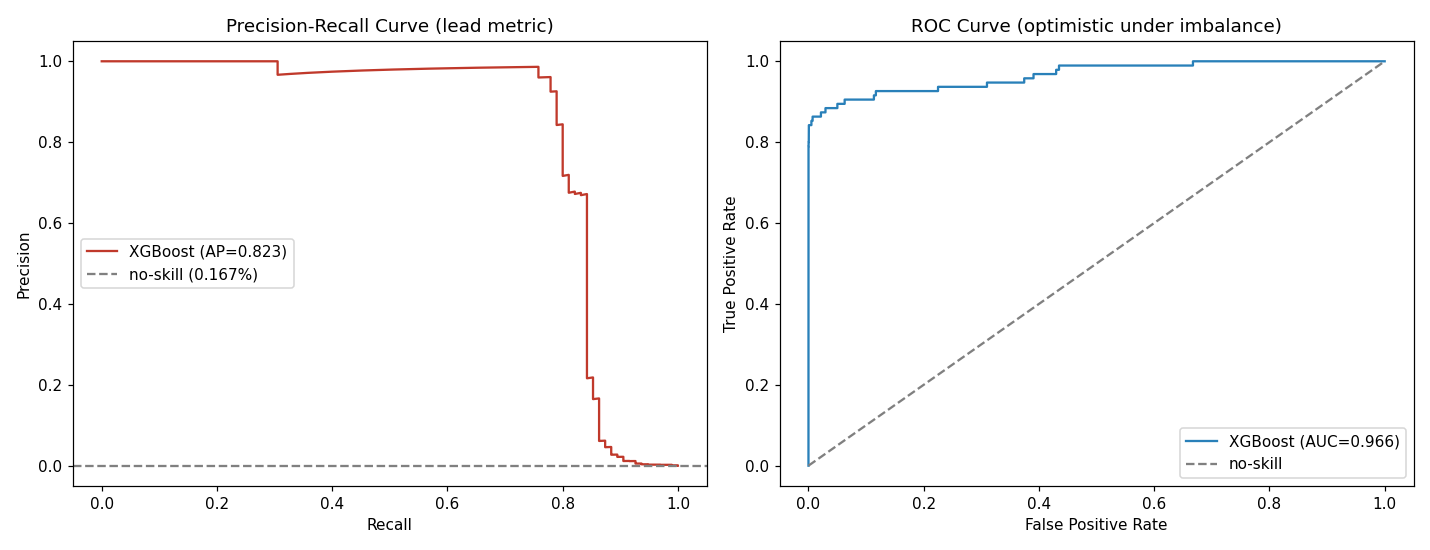

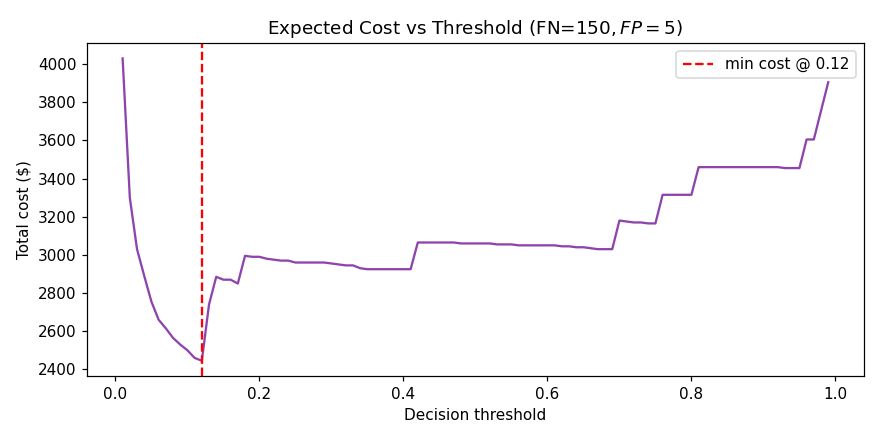

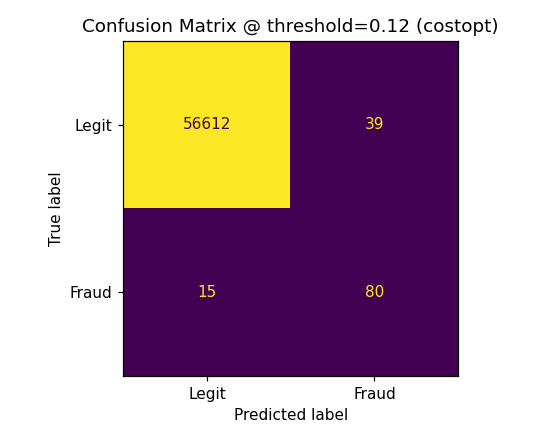

In [5]:
for f in ['06_pr_roc_curves.png', '07_cost_vs_threshold.png', '08_confusion_costopt.png']:
    display(Image(filename=str(FIG / f)))

## Conclusion
- **Best model:** XGBoost (PR-AUC 0.82).
- **Recommended threshold:** 0.12 (cost-optimal) — catches ~84% of fraud, ~20% lower expected cost than the default 0.50.
- **Honest caveat:** the optimal threshold depends on the FN/FP cost assumptions, which we parameterised rather than hard-coded.

See `reports/business_insights.md` for the stakeholder summary.